# Transistors

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
from PyLTSpice.editor.spice_editor import SpiceEditor

import ltspice_automation.sim as lt
import ltspice_automation.raw as rw
from ltspice_automation.paths import models_dir

BASE_DIR = models_dir("transistors")

## Tranzystor NPN - Charakterystyki

In [2]:
asc_path = (BASE_DIR / "npn.asc").resolve()

spice = SpiceEditor(str(asc_path))
spice.add_instructions(".MODEL BC547A NPN(IS=1.533E-14 ISE=7.932E-16 ISC=8.305E-14 XTI=3 BF=178.7 BR=8.628 IKF=0.1216 IKR=0.1121 XTB=1.5 VAF=69.7 VAR=44.7 VJE=0.4209 VJC=0.2 RE=0.6395 RC=0.6508 RB=1 RBM=1 IRB=1E-06 CJE=1.61E-11 CJC=4.388p XCJC=0.6193 FC=0.7762 NF=1.002 NR=1.004 NE=1.436 NC=1.207 MJE=0.3071 MJC=0.2793 TF=4.995E-10 TR=1m2 ITF=0.7021 VTF=3.523 XTF=139 EG=1.11 VCEO=50 ICRATING=100m MFG=PHILIPS)")
spice.set_component_value("R1", "100k")
spice.set_component_value("V2", "3")
raw_path = lt.run_sim(asc_path=asc_path, spice=spice,analysis_card=".dc V2 0 10 0.1", output_dir=asc_path.parent, run_name=asc_path.stem, wait_seconds=50)
rr = rw.read_raw(raw_path)
df = rw.raw_to_dataframe(rr)

lt.clear_sim_outputs(asc_path)

0094:err:winediag:is_broken_driver Broken NVIDIA RandR detected, falling back to RandR 1.0. Please consider using the Nouveau driver instead.
00dc:err:winediag:is_broken_driver Broken NVIDIA RandR detected, falling back to RandR 1.0. Please consider using the Nouveau driver instead.
0034:err:winediag:is_broken_driver Broken NVIDIA RandR detected, falling back to RandR 1.0. Please consider using the Nouveau driver instead.
00d4:err:winediag:is_broken_driver Broken NVIDIA RandR detected, falling back to RandR 1.0. Please consider using the Nouveau driver instead.
wine: Read access denied for device L"\\??\\Z:\\", FS volume label and serial are not available.
0134:err:winediag:is_broken_driver Broken NVIDIA RandR detected, falling back to RandR 1.0. Please consider using the Nouveau driver instead.
wine: Read access denied for device L"\\??\\Z:\\", FS volume label and serial are not available.
wine: Read access denied for device L"\\??\\Z:\\", FS volume label and serial are not available.

In [3]:
df

,x,I(V1),Ib(Q1),Is(Q1),V(b),V(n001),I(V2),Ic(Q1),Ie(Q1),I(R1),V2,I(R2),V(n002),V(c)
0,0.0,-1.010290e-11,-1.008482e-11,0.0,0.000001,10.0,1.008482e-11,1.010187e-11,-1.753114e-14,1.008482e-11,0.0,-1.010291e-11,0.0,10.000000
1,0.1,-1.081364e-11,-9.869924e-12,0.0,0.100001,10.0,9.869919e-12,1.081154e-11,-9.430734e-13,9.882336e-12,0.1,-1.007049e-11,0.1,10.000000
2,0.2,-4.900988e-11,-9.320017e-12,0.0,0.200001,10.0,9.320012e-12,4.900812e-11,-3.968956e-11,9.320015e-12,0.2,-4.900986e-11,0.2,10.000000
3,0.3,-1.858030e-09,2.201350e-12,0.0,0.300000,10.0,-2.201335e-12,1.858029e-09,-1.860232e-09,-2.201313e-12,0.3,-1.858032e-09,0.3,10.000000
4,0.4,-8.716906e-08,4.604751e-10,0.0,0.399954,10.0,-4.604751e-10,8.716906e-08,-8.762954e-08,-4.604744e-10,0.4,-8.716894e-08,0.4,9.999991
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96,9.6,-1.551112e-02,8.873012e-05,0.0,0.726988,10.0,-8.873012e-05,1.551112e-02,-1.559985e-02,-8.873012e-05,9.6,-1.551112e-02,9.6,8.448889
97,9.7,-1.566538e-02,8.972622e-05,0.0,0.727377,10.0,-8.972622e-05,1.566538e-02,-1.575511e-02,-8.972622e-05,9.7,-1.566538e-02,9.7,8.433462
98,9.8,-1.581929e-02,9.072236e-05,0.0,0.727764,10.0,-9.072236e-05,1.581929e-02,-1.591001e-02,-9.072236e-05,9.8,-1.581929e-02,9.8,8.418071
99,9.9,-1.597285e-02,9.171853e-05,0.0,0.728147,10.0,-9.171853e-05,1.597285e-02,-1.606457e-02,-9.171853e-05,9.9,-1.597285e-02,9.9,8.402715


### $I_B = f(U_{BE})$

<>:8: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
<>:9: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
<>:8: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
<>:9: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
/tmp/ipykernel_63975/1185651691.py:8: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
  ax.set_xlabel("$U_{BE} \  [V]$")
/tmp/ipykernel_63975/1185651691.py:9: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is

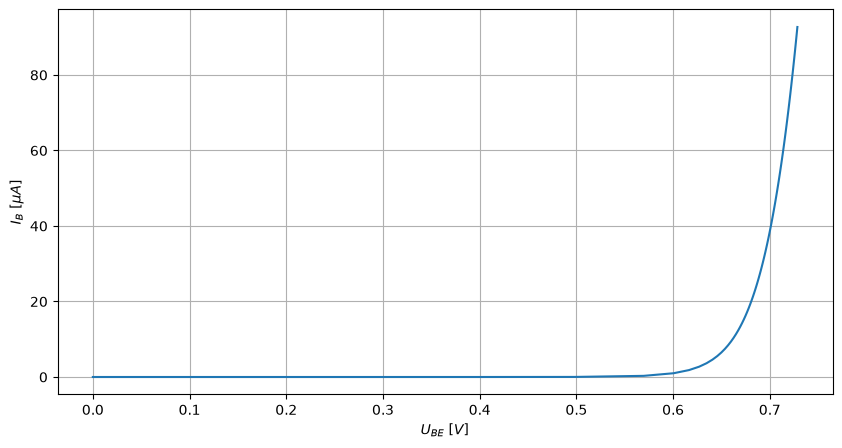

In [4]:
v_be = df["V(b)"]
i_b = df["Ib(Q1)"]*1e6


fig,ax = plt.subplots(figsize=(10, 5))
ax.plot(v_be, i_b)

ax.set_xlabel("$U_{BE} \  [V]$")
ax.set_ylabel("$I_B \ [\mu A]$")
ax.grid(True)

### $I_C = f(U_{CE})$

In [5]:
asc_path = (BASE_DIR / "npn.asc").resolve()

spice = SpiceEditor(str(asc_path))
spice.add_instructions(".MODEL BC547A NPN(IS=1.533E-14 ISE=7.932E-16 ISC=8.305E-14 XTI=3 BF=178.7 BR=8.628 IKF=0.1216 IKR=0.1121 XTB=1.5 VAF=69.7 VAR=44.7 VJE=0.4209 VJC=0.2 RE=0.6395 RC=0.6508 RB=1 RBM=1 IRB=1E-06 CJE=1.61E-11 CJC=4.388p XCJC=0.6193 FC=0.7762 NF=1.002 NR=1.004 NE=1.436 NC=1.207 MJE=0.3071 MJC=0.2793 TF=4.995E-10 TR=1m2 ITF=0.7021 VTF=3.523 XTF=139 EG=1.11 VCEO=50 ICRATING=100m MFG=PHILIPS)")
spice.add_instructions(".step param VB list 3 6 9")
spice.set_component_value("R1", "100k")
raw_path = lt.run_sim(asc_path=asc_path, spice=spice,analysis_card=".dc V1 0 10 0.1", output_dir=asc_path.parent, run_name=asc_path.stem, wait_seconds=50)
rr = rw.read_raw(raw_path)
df = rw.raw_to_dataframe(rr)
df = rw.raw_to_dataframes_by_step(rr)

lt.clear_sim_outputs(asc_path)

0094:err:winediag:is_broken_driver Broken NVIDIA RandR detected, falling back to RandR 1.0. Please consider using the Nouveau driver instead.
00dc:err:winediag:is_broken_driver Broken NVIDIA RandR detected, falling back to RandR 1.0. Please consider using the Nouveau driver instead.
0034:err:winediag:is_broken_driver Broken NVIDIA RandR detected, falling back to RandR 1.0. Please consider using the Nouveau driver instead.
00d4:err:winediag:is_broken_driver Broken NVIDIA RandR detected, falling back to RandR 1.0. Please consider using the Nouveau driver instead.
wine: Read access denied for device L"\\??\\Z:\\", FS volume label and serial are not available.
013c:err:winediag:is_broken_driver Broken NVIDIA RandR detected, falling back to RandR 1.0. Please consider using the Nouveau driver instead.
wine: Read access denied for device L"\\??\\Z:\\", FS volume label and serial are not available.
wine: Read access denied for device L"\\??\\Z:\\", FS volume label and serial are not available.

<>:13: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
<>:14: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
<>:13: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
<>:14: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
/tmp/ipykernel_63975/3958157296.py:13: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
  ax.set_xlabel("$U_{CE} \  [V]$", fontdict={'size': 14})
/tmp/ipykernel_63975/3958157296.py:14: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did yo

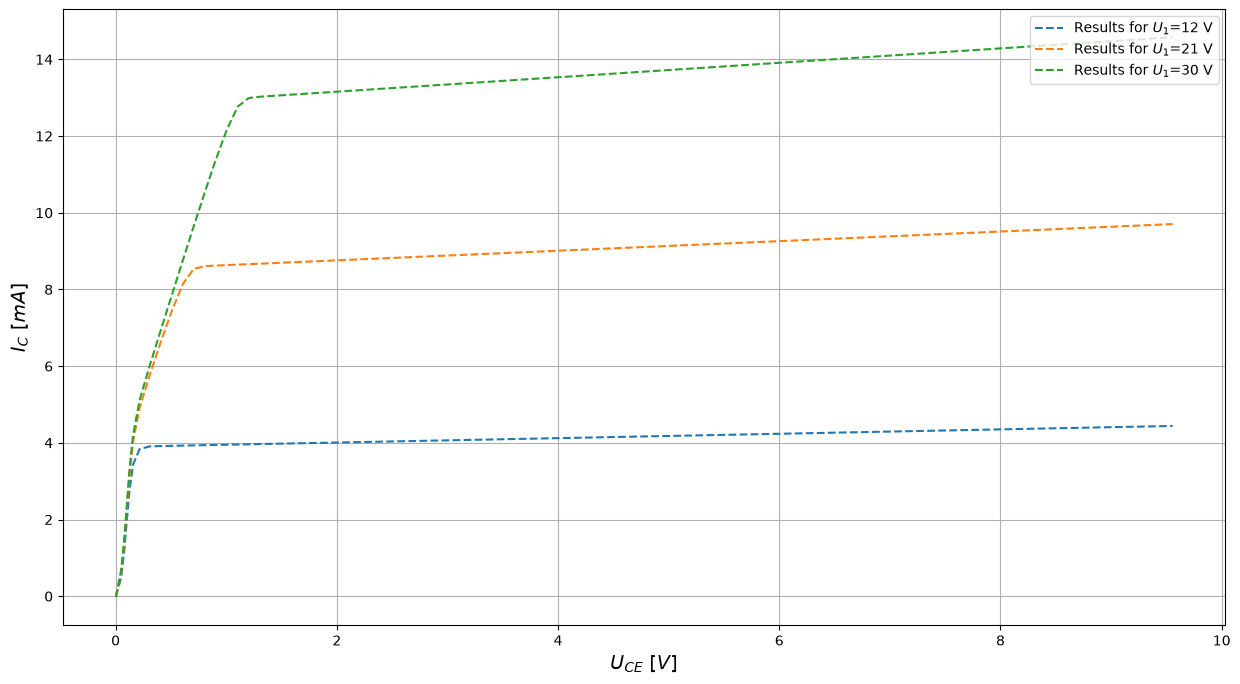

In [8]:
v_ce = df[3]["V(c)"]
i_c = {}
v_ce_pom = {}
i_c_pom = {}

for key, step in df.items():
    i_c[key] = step["Ic(Q1)"]*1e3

fig,ax = plt.subplots(figsize=(15, 8))
for step, i_c in i_c.items():
    ax.plot(v_ce, i_c, label=f"Results for $U_1$={3+3*step} V", linestyle="--")

ax.set_xlabel("$U_{CE} \  [V]$", fontdict={'size': 14})
ax.set_ylabel("$I_C \ [mA]$", fontdict={'size': 14})
ax.grid(True)
ax.legend(loc='upper right', bbox_to_anchor=(1, 1))
# ax.set_ylim(0,23)


## JFET

In [9]:
asc_path = (BASE_DIR / "jfet.asc").resolve()

spice = SpiceEditor(str(asc_path))
spice.add_instructions(".MODEL BF256B NJF(VTO=-3 BETA=1.09m BETATCE=-0.5 LAMBDA=2.31754E-2 RD=7.77648 RS=7.77648 CGS=2.00000p CGD=2.20000p PB=9.91494E-1 IS=2.59121E-16 XTI=3 AF=1 FC=0.5 N=1 NR=2 MFG=PHILIPS)")
raw_path = lt.run_sim(asc_path=asc_path, spice=spice,analysis_card=".dc V2 -5 0 0.1", output_dir=asc_path.parent, run_name=asc_path.stem, wait_seconds=50)
rr = rw.read_raw(raw_path)
df = rw.raw_to_dataframe(rr)

lt.clear_sim_outputs(asc_path)


0094:err:winediag:is_broken_driver Broken NVIDIA RandR detected, falling back to RandR 1.0. Please consider using the Nouveau driver instead.
00dc:err:winediag:is_broken_driver Broken NVIDIA RandR detected, falling back to RandR 1.0. Please consider using the Nouveau driver instead.
0034:err:winediag:is_broken_driver Broken NVIDIA RandR detected, falling back to RandR 1.0. Please consider using the Nouveau driver instead.
00d4:err:winediag:is_broken_driver Broken NVIDIA RandR detected, falling back to RandR 1.0. Please consider using the Nouveau driver instead.
wine: Read access denied for device L"\\??\\Z:\\", FS volume label and serial are not available.
0134:err:winediag:is_broken_driver Broken NVIDIA RandR detected, falling back to RandR 1.0. Please consider using the Nouveau driver instead.
wine: Read access denied for device L"\\??\\Z:\\", FS volume label and serial are not available.
wine: Read access denied for device L"\\??\\Z:\\", FS volume label and serial are not available.

<>:7: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
<>:8: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
<>:7: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
<>:8: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
/tmp/ipykernel_63975/3974966840.py:7: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
  ax.set_xlabel("$U_{GS} \  [V]$")
/tmp/ipykernel_63975/3974966840.py:8: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is

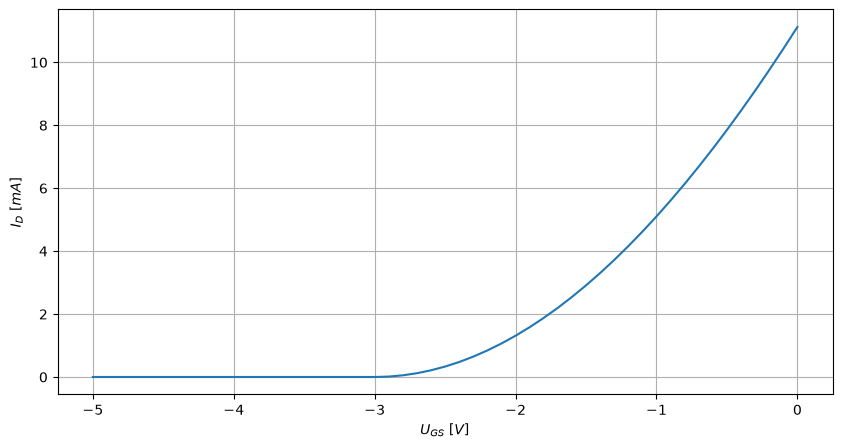

In [10]:
v_ce = df[("V(g)")]
i_d = df[("Id(J1)")] * 1e3

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(v_ce, i_d)

ax.set_xlabel("$U_{GS} \  [V]$")
ax.set_ylabel("$I_D \ [mA]$")
ax.grid(True)
